In [27]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon
import os
import sys

sys.path.append("..")
from src.py.proj_conf import *

## Read in Basinmaker Routing Product and WSC Outlet Point

In [28]:
# Read BasinMaker shapefile
basins_gdf = gpd.read_file(DATA_RAW + "Basinmaker_RoutingProduct/drainage_region_0004_00015_v2-1/finalcat_info_v2-1.shp")

# Read WSC outlet point metadata
wsc_dp = pd.read_csv(DATA_RAW + "WSC_data/station_metadata_historical.csv")


## Select Manning Cannal Subbasins

In [29]:
# Convert csv to geodataframe
wsc_dp_gdf = gpd.GeoDataFrame(
    wsc_dp,
    geometry = gpd.points_from_xy(
        x = wsc_dp.Longitude,
        y = wsc_dp.Latitude,
        crs = 'EPSG:4326', # or: crs = pyproj.CRS.from_user_input(4326)
    )
)

In [30]:
# Identify initial subbasin containing WSC outlet point
point = wsc_dp_gdf.geometry
for i, row in basins_gdf.iterrows():
    if row.geometry.contains(point).any():
        dp = row['SubId']
        break


## Old code. Deprecated.
# basins_gdf['contains_point'] = gdf.geometry.contains(point, align = False)
# # wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')
# wsc_basins = basins_gdf[basins_gdf['contains_point'] == True]
# dp = wsc_basins['SubId'].values
# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

4076245


In [31]:
# Create list containing inital Manning Canal subbasins and its upstream subbasin
for i, row in basins_gdf.iterrows():
    if row['DowSubId'] == dp:
        sub_select = [row['DowSubId'], row['SubId']]

print(sub_select)

[4076245, 4076244]


In [32]:
# Add subbasins to Manning Canal list if they are connected to previously added subbasins (via DowSubId field)
n = 0
while n == 0:
    for i, row in basins_gdf.iterrows():
        if row['DowSubId'] in sub_select and row['SubId'] not in sub_select:
            sub_select.append(row['SubId'])
            break
    else:
        n = 1
print(sub_select)

[4076245, 4076244, 4076298, 4075410, 4076349, 4076348, 4076546, 4076565, 4075680, 4075849, 4075841, 4074754, 4076027, 4076058, 4075203, 4075219, 4076596, 4076041, 4076439, 4076610, 4076611, 4075700, 4075707]


(np.float64(-96.95441666664995),
 np.float64(-96.47225000034994),
 np.float64(49.35354166300007),
 np.float64(49.66979166300004))

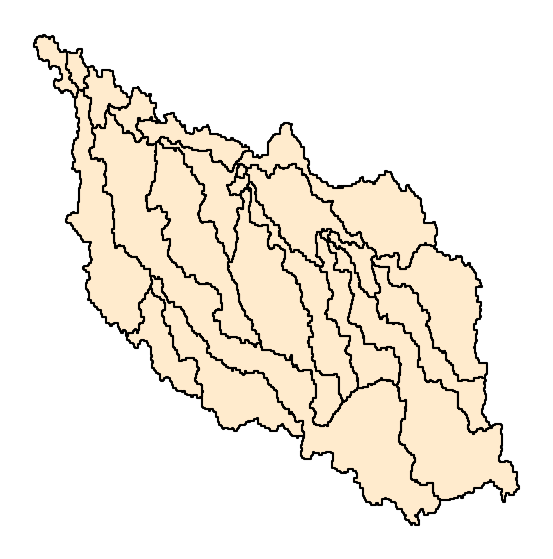

In [33]:

# Create geodataframe containing Manning Canal subbasins
mc_gdf = basins_gdf[basins_gdf['SubId'].isin(sub_select)]

# Plot Manning Canal subbasins
f, ax = plt.subplots(1,1,figsize=(7,7))
mc_gdf.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
ax.axis('off')

## Delineate Upper Manning with Whitebox

In [ ]:
import sys
!{sys.executable} -m pip install whitebox
import whitebox
wbt = whitebox.WhiteboxTools()

import math
import rasterio
import rasterio.plot

In [26]:
# Set working directory
wbt.set_working_dir(DATA_RAW + "DEMs")

# Fill depressions in DEM
wbt.fill_depressions(
    dem = "sr_dem_cgvd28_Resamp_1.tif",
    output = "mc_filldep.tif",
    fix_flats=True,
    flat_increment=None,
    max_depth=None
)

# Breach depressions in DEM
wbt.breach_depressions_least_cost(
    dem = "sr_dem_cgvd28_Resamp_1.tif",
    output = "mc_breachdep.tif", 
    dist = 1000, 
    max_cost=None, 
    min_dist=True, 
    flat_increment=None, 
    fill=True
)

# Create flow accumulation raster
wbt.d8_flow_accumulation(
    i = "mc_breachdep.tif", 
    output = "mc_flowaccgrid.tif", 
    out_type="cells", 
    log=False, 
    clip=False, 
    pntr=False, 
    esri_pntr=False
)

# Extract streams from flow accumulation raster
wbt.extract_streams(
    flow_accum='mc_flowaccgrid.tif', 
    output='mc_streams_90000.tif', 
    threshold=90000.000000, 
    zero_background=True, 
)

# Create flow pointer (flow direction) raster
wbt.d8_pointer(
    dem = "mc_breachdep.tif",
    output = "mc_flowpointergrid.tif",
    esri_pntr=False
)

# Snap pour points to stream network
wbt.jenson_snap_pour_points(
    pour_pts = "mc_pp_extract.shp", 
    streams = "mc_streams_90000.tif", 
    output = "mc_pp_snap_2000m.shp", 
    snap_dist = 2000.0
)

# Derive watershed areas
wbt.watershed(
    d8_pntr = 'mc_flowpointergrid.tif', 
    pour_pts = 'mc_pp_snap_2000m.shp', 
    output = 'mc_watershed.tif', 
    esri_pntr=False
)

.\whitebox_tools.exe --run="FillDepressions" --wd="..\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_filldep.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
thread 'main' panicked at whitebox-tools-app\src\main.rs:72:21:
The system cannot find the path specified. (os error 3)
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace
.\whitebox_tools.exe --run="BreachDepressionsLeastCost" --wd="..\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_breachdep.tif' --dist='1000' --min_dist --fill -v --compress_rasters=False

*****************************************
* Welcome to BreachDepressionsLeastCost *
* Powered by WhiteboxTools              *
* www.whiteboxgeo.com                   *
*****************************************
Reading data...
thread 'main' 

0

In [21]:








# Visualize Manning Canal watershed raster
data_name = DATA_RAW + "DEMs/mc_watershed.tif"
tiff = rasterio.open(data_name)
rasterio.plot.show(tiff, title = "MC Watershed Delineation")

.\whitebox_tools.exe --run="FillDepressions" --wd="..\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_filldep.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
thread 'main' panicked at whitebox-tools-app\src\main.rs:72:21:
The system cannot find the path specified. (os error 3)
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace
.\whitebox_tools.exe --run="BreachDepressionsLeastCost" --wd="..\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_breachdep.tif' --dist='1000' --min_dist --fill -v --compress_rasters=False

*****************************************
* Welcome to BreachDepressionsLeastCost *
* Powered by WhiteboxTools              *
* www.whiteboxgeo.com                   *
*****************************************
Reading data...
thread 'main' 

RasterioIOError: ../Data\Raw\manning/DEMs/mc_watershed.tif: No such file or directory